# 01 – TurkCanon raw data exploration

Goal: understand the raw TurkCanon documents before fixing the preprocessing rules.

- This notebook **only reads** `data/raw/TurkCanon/`; it writes nothing.
- Random samples use a fixed seed, so everyone sees the same examples.
- Each section starts with a question and ends with a **Notes** cell. Write findings there: they become preprocessing decisions and the *Dataset Analysis* part of the report.
- The regexes here are exploratory. Final rules will move to the preprocessing code.

**How to use:** run the cells from top to bottom. Later sections reuse objects built earlier: `df` in section 0, `MADDE` in section 3, and `art` in section 5. Each code cell is preceded by a short note: what it does, what it outputs, how to read it.

## 0. Setup

<!-- explain -->
**What it does:** loads `train.jsonl`, `dev.jsonl` and `test.jsonl` into one table `df`. One row is one document, with columns:
- `doc_id`, `source`, `text`, `label` (raw fields);
- `split` (`train` / `dev` / `test`);
- `n_words` (word count).

Details:
- `find_repo_root` locates the repo, so the data path works whatever folder the notebook is started from.
- `split` and `label` are ordered categories, so every table lists them in the same order.
- The `assert` stops the notebook if an unexpected label appears.

**Output:** the repo path and the first 5 rows of `df`.

In [5]:
import bisect
import hashlib
import re
import textwrap
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
SEED = 42


def find_repo_root(start=None):
    start = Path.cwd() if start is None else start
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "data" / "raw").exists():
            return p
    raise FileNotFoundError("Repo root not found; open the notebook inside the repo.")


ROOT = find_repo_root()
RAW = ROOT / "data" / "raw" / "TurkCanon"
SPLITS = ["train", "dev", "test"]
LABELS = ["YONETMELIK", "TEBLIG", "KANUN", "CUMHURBASKANLIGI_YONETMELIGI", "TUZUK",
          "KANUN_HUKMUNDE_KARARNAME", "CUMHURBASKANLIGI_KARARNAMESI"]

df = pd.concat([pd.read_json(RAW / f"{s}.jsonl", lines=True).assign(split=s) for s in SPLITS],
               ignore_index=True)
assert df["label"].isin(LABELS).all(), "unexpected label"
df["split"] = pd.Categorical(df["split"], SPLITS, ordered=True)
df["label"] = pd.Categorical(df["label"], LABELS, ordered=True)
df["n_words"] = df["text"].str.split().str.len()
print(ROOT)
df.head()

/Users/burakzor/Desktop/legal-tr-article-clf


,doc_id,source,text,label,split,n_words
0,LEG-a32ff45b2e68,legislative,"DENETİMLİ SERBESTLİK HİZMETLERİ [MASK] BİRİNCİ KISIM Genel Hükümler BİRİNCİ BÖLÜM Amaç, Kapsam, Dayanak ve Tanımlar Amaç MADDE 1 –( 1) Bu [MASK] amacı; Denetimli Serbestlik Daire Başkanlığı, denet...",YONETMELIK,train,22794
1,LEG-d0f7471cdb78,legislative,AİLE VE SOSYAL HİZMETLER BAKANLIĞI DİSİPLİN AMİRLERİ [MASK] Amaç MADDE 1- (1) Bu [MASK] amacı; Aile ve Sosyal Hizmetler Bakanlığında görev yapan Devlet memurlarının disiplin amirlerini belirlemekt...,YONETMELIK,train,192
2,LEG-7711c7336536,legislative,"KADASTRO ÇALIŞMA ALANLARINDAKİ TAŞINMAZ MALLARA GİREBİLECEK GÖREVLİLER HAKKINDA [MASK] BİRİNCİ BÖLÜM Amaç ve Dayanak Amaç Madde 1 - Bu [MASK] amacı, kadastrosu yapılan çalışma alanları içerisindek...",YONETMELIK,train,517
3,LEG-e3f1a487d8f9,legislative,BÜYÜKŞEHİR BELEDİYESİ SINIRLARI İÇERİSİNDE İLÇE KURULMASI VE BAZI [MASK] DEĞİŞİKLİK YAPILMASI HAKKINDA [MASK] Numarası : 5747 Kabul Tarihi : 6/3/2008 Yayımlandığı Resmî Gazete : Tarih : 22/3/2008 ...,KANUN,train,12279
4,LEG-929703d493d4,legislative,Kurum Hazine Müsteşarlığı [MASK] Adı Ham Elmas Dış Ticaretinin Düzenlenmesine ve Denetlenmesine Dair Karar’a İlişkin [MASK] No 2006/1 Resmî Gazete Tarihi 15/11/2006 Resmî Gazete Sayısı 26347 HAM E...,TEBLIG,train,955


<!-- explain -->
**What it does:** defines two helpers used later.
- `show_doc(doc_id, start, length)` prints part of one document, wrapped to 120 characters. The first line shows `doc_id | label | split | words | which characters are shown`.
- `find_context(pattern, texts, n)` searches a regex in many texts and prints `n` random matches, each with 80 characters of surrounding text and the `doc_id` it comes from. It then prints the total number of matches.

**Output:** none (only definitions).

In [6]:
def show_doc(doc_id, start=0, length=4000, width=120):
    """Print part of a document, wrapped for reading."""
    row = df.loc[df["doc_id"] == doc_id].iloc[0]
    text = row["text"]
    end = min(start + length, len(text))
    print(f"{row['doc_id']} | {row['label']} | {row['split']} | {row['n_words']} words | "
          f"chars {start}-{end} of {len(text)}")
    print("-" * width)
    print(textwrap.fill(text[start:end], width=width))


def find_context(pattern, texts, n=5, window=80, seed=SEED):
    """Show n random matches of a regex with surrounding text. `texts` is a Series indexed by doc_id."""
    rx = re.compile(pattern)
    hits = [(doc_id, t[max(0, m.start() - window):m.end() + window])
            for doc_id, t in texts.items() for m in rx.finditer(t)]
    rng = np.random.default_rng(seed)
    for i in rng.permutation(len(hits))[:n]:
        doc_id, ctx = hits[i]
        print(f"[{doc_id}] ...{' '.join(ctx.split())}...")
    print(f"({len(hits)} matches in total)")

## 1. What does the data look like?
Fields, split sizes, class distribution, document lengths.

<!-- explain -->
**What it does:** basic facts about the dataset.

**Output:**
1. The column names and the values of `source`. There is only one value, so the field is not useful.
2. **Documents per class × split** (`All` = totals).
3. **The same table as % of each split** (each column sums to 100).

**How to read it:**
- If the percentages are almost equal across the three columns, the official split is stratified.
- Small counts in `dev` show which classes will give noisy validation scores.

In [7]:
print("columns:", df.columns.tolist())
print(df["source"].value_counts(), "\n")
display(pd.crosstab(df["label"], df["split"], margins=True))
display(pd.crosstab(df["label"], df["split"], normalize="columns").mul(100).round(1))

columns: ['doc_id', 'source', 'text', 'label', 'split', 'n_words']
source
legislative    9126
Name: count, dtype: int64 



split,train,dev,test,All
label,,,,
YONETMELIK,2812,401,805,4018
TEBLIG,2573,367,736,3676
KANUN,635,90,183,908
CUMHURBASKANLIGI_YONETMELIGI,222,31,65,318
TUZUK,76,10,23,109
KANUN_HUKMUNDE_KARARNAME,44,6,13,63
CUMHURBASKANLIGI_KARARNAMESI,23,3,8,34
All,6385,908,1833,9126


split,train,dev,test
label,,,
YONETMELIK,44.0,44.2,43.9
TEBLIG,40.3,40.4,40.2
KANUN,9.9,9.9,10.0
CUMHURBASKANLIGI_YONETMELIGI,3.5,3.4,3.5
TUZUK,1.2,1.1,1.3
KANUN_HUKMUNDE_KARARNAME,0.7,0.7,0.7
CUMHURBASKANLIGI_KARARNAMESI,0.4,0.3,0.4


<!-- explain -->
**What it does:** draws the documents-per-class table above as a bar chart, one bar per split.

**Output:** a figure that can be used in the report (*Dataset Analysis*).

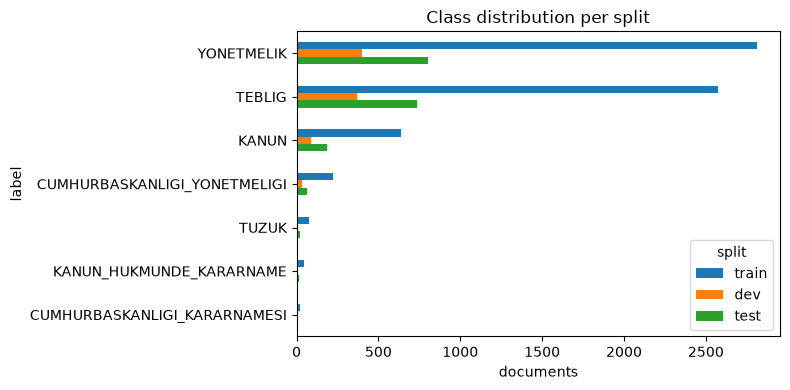

In [8]:
ax = pd.crosstab(df["label"], df["split"]).plot.barh(figsize=(8, 4))
ax.invert_yaxis()
ax.set_xlabel("documents")
ax.set_title("Class distribution per split")
plt.tight_layout()
plt.show()

<!-- explain -->
**What it does:** document length statistics, in words.

**Output:**
1. A table per class:
   - `count` = documents;
   - `mean` / `std` = average and spread;
   - `min`;
   - `50%` = median;
   - `90%` = 90% of documents are shorter than this;
   - `max`.
2. A histogram of document lengths per class. The x axis is logarithmic because lengths range from ~10 to millions of words.

**How to read it:**
- Use the median rather than the mean; a few huge documents pull the mean up.
- A very large `max` points to outliers worth opening with `show_doc`.

,count,mean,std,min,50%,90%,max
label,,,,,,,
YONETMELIK,4018.0,4962.0,56787.0,16.0,2532.0,8130.0,3577844.0
TEBLIG,3676.0,2069.0,6222.0,24.0,802.0,4274.0,176940.0
KANUN,908.0,4451.0,9354.0,65.0,1500.0,10424.0,125766.0
CUMHURBASKANLIGI_YONETMELIGI,318.0,4885.0,7736.0,131.0,2882.0,9882.0,109084.0
TUZUK,109.0,3565.0,5448.0,217.0,2096.0,8117.0,46664.0
KANUN_HUKMUNDE_KARARNAME,63.0,2470.0,5170.0,104.0,850.0,5334.0,36105.0
CUMHURBASKANLIGI_KARARNAMESI,34.0,8342.0,25853.0,84.0,1400.0,5205.0,114940.0


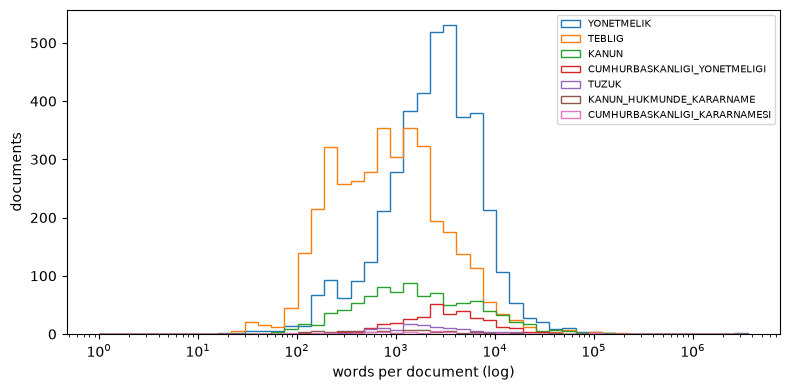

In [9]:
display(df.groupby("label")["n_words"].describe(percentiles=[0.5, 0.9]).round(0))

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0, np.log10(df["n_words"].max() + 1), 50)
for lab in LABELS:
    ax.hist(df.loc[df["label"] == lab, "n_words"], bins=bins, histtype="step", label=lab)
ax.set_xscale("log")
ax.set_xlabel("words per document (log)")
ax.set_ylabel("documents")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Notes (1):**

-

## 2. What do the documents look like? (most important section)
Two random train documents per class (14 in total). Read them from start to end: how does the header look, how do articles start, what else is mixed in?

<!-- explain -->
**What it does:** picks 2 random train documents per class (fixed seed) for reading.

**Output:** a table of the 14 sampled documents (`doc_id`, `label`, length). The row number is the `i` used in the next cell.

In [10]:
sample_docs = (df[df["split"] == "train"]
               .groupby("label", group_keys=False)
               .sample(n=2, random_state=SEED)[["doc_id", "label", "n_words"]]
               .reset_index(drop=True))
sample_docs

,doc_id,label,n_words
0,LEG-27c4b64a9402,YONETMELIK,1738
1,LEG-555c2d3663a5,YONETMELIK,2469
2,LEG-277d315ba467,TEBLIG,1131
3,LEG-bf9db7b8d671,TEBLIG,815
4,LEG-6e820bf9a3b7,KANUN,1503
5,LEG-01c3cfbe4982,KANUN,303
6,LEG-059660bac91c,CUMHURBASKANLIGI_YONETMELIGI,9166
7,LEG-bb42f219d47c,CUMHURBASKANLIGI_YONETMELIGI,1502
8,LEG-44c7bf9fe403,TUZUK,2093
9,LEG-3c2481ab48ea,TUZUK,1466


<!-- explain -->
**What it does:** prints sample document number `i`, 4000 characters at a time.

**How to use:**
- Change `i` (0–13) to switch documents.
- Increase `start` (4000, 8000, …) to read further into a long document.
- While reading, look at how the header ends, how each `MADDE` starts, and what else is mixed into the text.

In [11]:
i = 0          # 0..13: which sample document
start = 0      # increase (e.g. 4000, 8000, ...) to continue a long document
show_doc(sample_docs.loc[i, "doc_id"], start=start, length=4000)

LEG-27c4b64a9402 | YONETMELIK | train | 1738 words | chars 0-4000 of 13125
------------------------------------------------------------------------------------------------------------------------
SOSYAL SİGORTA YÜKSEK SAĞLIK KURULUNUN GÖREV, YETKİ, ÇALIŞMA USUL VE ESASLARI HAKKINDA [MASK] BİRİNCİ BÖLÜM Amaç ve
Kapsam, Dayanak ve Tanımlar Amaç ve kapsam MADDE 1 – (1) Bu [MASK] amacı, Sosyal Sigorta Yüksek Sağlık Kurulunun, görev,
yetki, çalışma usul ve esasları ile kurul üyelerinin hak ve yükümlülüklerini düzenlemektir. Dayanak MADDE 2 – (1) Bu
[MASK], 5510 sayılı Sosyal Sigortalar ve Genel Sağlık Sigortası [MASK] 14 üncü maddesinin altıncı fıkrası ve 58 inci
maddesi hükümlerine dayanılarak hazırlanmıştır. Tanımlar MADDE 3 – (1) Bu [MASK] geçen; a) Bakanlık: Çalışma ve Sosyal
Güvenlik Bakanlığını, b) Başkan: Sosyal Sigorta Yüksek Sağlık Kurulu Başkanını, c) Daire Başkanlığı: Sosyal Sigorta
Yüksek Sağlık Kurulunun sekretarya görevini yürütmek üzere Sosyal Güvenlik Kurumu Yönetim Kurulunc

**Notes (2):**

-

## 3. Where does the header end?
Header = everything before the first `MADDE` marker. Does it carry type cues?

<!-- explain -->
**What it does:**
1. Imports the article marker regex of the preprocessing code (`MARKER` in `src/legalclf/preprocessing/segment.py`) as `MADDE`. It matches:
   - an optional prefix `GEÇİCİ` / `MUVAKKAT` (old word for temporary) / `EK` / `MÜKERRER`;
   - `MADDE` or `Madde`, then a number;
   - an optional `/A`;
   - an optional paragraph number `(1)`;
   - then a dash or a colon. Six dash characters are accepted: `-`, `–`, `—`, `‒` (U+2012), `−` (U+2212), `―` (U+2015).

   Examples: `MADDE 1 –`, `Madde 12-`, `GEÇİCİ MADDE 3 –`, `Muvakkat Madde 1 -`, `Madde 5/A-`, `MADDE 2(1) –`.

   The last three dash characters, `MUVAKKAT` and the `(1)` form were added after the sequence check in section 4 showed articles missed because of them.
2. For each document, finds the first marker. Everything before it becomes `header`; `has_madde` records whether any marker was found.

**Output:** header length in words per class (same columns as in section 1). Documents without any `MADDE` have no header and are not counted.

**How to read it:** typical headers are short. A very large `max` means the first marker appears very late, either because the regex misses the real markers or because the document starts with something else (annexes, tables).

In [ ]:
# article marker regex of the preprocessing code (src/legalclf/preprocessing/segment.py)
from legalclf.preprocessing.segment import MARKER as MADDE

first = df["text"].map(lambda t: m.start() if (m := MADDE.search(t)) else -1)
df["has_madde"] = first >= 0
df["header"] = [t[:p] if p >= 0 else None for t, p in zip(df["text"], first)]
df["header_words"] = df["header"].str.split().str.len()
df.groupby("label")["header_words"].describe(percentiles=[0.5, 0.9]).round(0)

<!-- explain -->
**What it does:** prints 3 random headers per class (first 300 characters).

**How to read it:** look for words in the header that reveal the type (law numbers, "Kabul Tarihi", "SIRA NO", …).

In [13]:
for lab in LABELS:
    sub = df[(df["label"] == lab) & df["has_madde"]]
    print(f"=== {lab}")
    for h in sub.sample(min(3, len(sub)), random_state=SEED)["header"]:
        print("   ", " ".join(h.split())[:300])

=== YONETMELIK
    LİMAN DEVLETİ DENETİMİ [MASK] BİRİNCİ BÖLÜM Amaç, Kapsam, Dayanak ve Tanımlar Amaç
    MİLLÎ EĞİTİM BAKANLIĞI ÖZEL MOTORLU TAŞIT SÜRÜCÜLERİ KURSU [MASK] BİRİNCİ BÖLÜM Amaç, Kapsam, Dayanak ve Tanımlar Amaç
    SAĞLIK BAKANLIĞINCA YAPILACAK PİYASA GÖZETİMİ VE DENETİMİNİN USUL VE ESASLARI HAKKINDA [MASK] BİRİNCİ BÖLÜM Amaç, Kapsam, Dayanak ve Tanımlar Amaç
=== TEBLIG
    MİLLİ EMLAK GENEL [MASK] (SIRA NO: 373) BİRİNCİ BÖLÜM Amaç, Kapsam, Dayanak ve Tanımlar Amaç ve kapsam
    İTHALATTA HAKSIZ REKABETİN ÖNLENMESİNE İLİŞKİN [MASK] ([MASK] NO: 2019/38) Amaç ve kapsam
    İTHALATTA KOTA VE TARİFE KONTENJANI İDARESİNE İLİŞKİN [MASK] ([MASK] NO: 2020/7) Amaç ve kapsam
=== KANUN
    BAZI ALACAKLARIN YENİDEN YAPILANDIRILMASI İLE BAZI [MASK] VE BİR [MASK] HÜKMÜNDE [MASK] DEĞİŞİKLİK YAPILMASINA DAİR [MASK]12 [MASK] Numarası : 7020 Kabul Tarihi : 18/5/2017 Yayımlandığı R.Gazete : Tarih : 27/5/2017 Sayı : 30078 Yayımlandığı Düstur : Tertip : 5 Cilt : 58 Kapsam ve tanımlar
    ATAT

<!-- explain -->
**What it does:** for each cue phrase, the % of documents per class whose header contains it.

**Output:** a table, rows = classes, columns = cue phrases.

**How to read it:** a column that is close to 100 in one row and close to 0 in the others means the cue almost *is* the label. A model could then classify from the header alone, which is why we remove the header.

In [14]:
# % of documents (with at least one MADDE) whose header contains the cue
CUES = {
    "Kabul Tarihi": r"Kabul Tarihi",
    "HÜKMÜNDE": r"HÜKMÜNDE",
    "Bakanlar Kurulu": r"Bakanlar Kurulu",
    "SERİ NO": r"SERİ NO|Seri No",
    "CUMHURBAŞKANLIĞI [MASK]": r"CUMHURBAŞKANLIĞI \[MASK\]",
}
hdr = df[df["has_madde"]]
pd.DataFrame({name: hdr.groupby("label")["header"].apply(lambda s, p=p: s.str.contains(p).mean() * 100)
              for name, p in CUES.items()}).round(1)

,Kabul Tarihi,HÜKMÜNDE,Bakanlar Kurulu,SERİ NO,CUMHURBAŞKANLIĞI [MASK]
label,,,,,
YONETMELIK,0.0,0.1,0.1,0.0,0.0
TEBLIG,0.0,0.3,1.3,11.6,0.0
KANUN,99.7,9.4,0.1,0.0,0.1
CUMHURBASKANLIGI_YONETMELIGI,0.0,0.0,71.2,0.0,0.0
TUZUK,0.9,0.0,95.4,0.0,0.0
KANUN_HUKMUNDE_KARARNAME,0.0,100.0,1.7,0.0,0.0
CUMHURBASKANLIGI_KARARNAMESI,0.0,0.0,0.0,0.0,100.0


**Notes (3):**

-

## 4. How are articles written?
Spelling variants of the `MADDE` marker, markers our regex misses, documents without any `MADDE`, articles per document.

<!-- explain -->
**What it does:** counts the spelling variants of the markers our regex matches. `shape()` replaces numbers with `N` and normalizes spaces, so `MADDE 12 –` and `MADDE 3 –` both count as `MADDE N –`.

**Output:** the 25 most frequent variants with their counts.

**How to read it:**
- Shows which forms the splitting rule must handle.
- Odd rare forms (e.g. `MADDEN –`, a missing space) are typos in the source.

In [15]:
def shape(s):
    return re.sub(r"\d+", "N", re.sub(r"\s+", " ", s))

variants = Counter(shape(m.group()) for t in df["text"] for m in MADDE.finditer(t))
pd.Series(variants, name="count").sort_values(ascending=False).head(25)

MADDE N –           89805
MADDE N-            31686
Madde N –           22969
Madde N-            13790
Madde N —            9398
Madde N -            5529
GEÇİCİ MADDE N –     3250
Geçici Madde N –     3006
MADDE N -            2693
GEÇİCİ MADDE N-      1464
Madde N–             1209
Ek Madde N –         1205
MADDE N–             1146
Geçici Madde N-      1092
MADDE N/A –           477
Ek Madde N-           440
MADDE N/A-            289
GEÇİCİ MADDE N–       269
Geçici Madde N -      224
Geçici Madde N —      206
MADDE N —             204
EK MADDE N –          197
EK MADDE N-           189
MADDEN –              142
MADDE N/B –           117
Name: count, dtype: int64

<!-- explain -->
**What it does:**
- Searches with a looser pattern `BROAD`: `MADDE`/`Madde` + number, with no dash required.
- Keeps only the matches that our strict regex did **not** match. These are the candidates our splitting misses.

**Output:**
1. % of documents per class with at least one missed occurrence.
2. The most common shapes of the missed occurrences.
3. 10 random missed occurrences with context.

**How to read it:** for each missed form decide:
- Is it a **real article start** written without a dash (e.g. old laws)? Then the regex must be extended.
- Or is it an **in-text reference** ("Madde 2.1.2 kapsamında")? Then it must not be split.

In [31]:
# "MADDE/Madde + number" occurrences that are NOT inside a match of our regex
BROAD = re.compile(r"(?:MADDE|Madde)\s*\d+\S{0,3}")

def missed_matches(t):
    spans = [(m.start(), m.end()) for m in MADDE.finditer(t)]
    starts = [a for a, _ in spans]
    out = []
    for m in BROAD.finditer(t):
        k = bisect.bisect_right(starts, m.start()) - 1
        if k < 0 or m.start() >= spans[k][1]:
            out.append((shape(m.group()), " ".join(t[max(0, m.start() - 60):m.end() + 60].split())))
    return out

missed = df["text"].map(missed_matches)
print("documents with at least one missed marker (%):")
print((missed.str.len() > 0).groupby(df["label"]).mean().mul(100).round(1))
all_missed = [x for lst in missed for x in lst]
print("\nmost common missed shapes:", Counter(s for s, _ in all_missed).most_common(30))
rng = np.random.default_rng(SEED)
for j in rng.permutation(len(all_missed))[:30]:
    print("  ...", all_missed[j][1], "...")

documents with at least one missed marker (%):
label
YONETMELIK                       7.3
TEBLIG                           4.0
KANUN                           54.7
CUMHURBASKANLIGI_YONETMELIGI    24.2
TUZUK                            7.3
KANUN_HUKMUNDE_KARARNAME        44.4
CUMHURBASKANLIGI_KARARNAMESI    26.5
Name: text, dtype: float64

most common missed shapes: [('Madde N', 5017), ('Madde N,', 2868), ('MADDE N', 2540), ('Madde N.N.', 792), ('MADDE N.', 340), ('Madde N.N', 256), ('Madde N.N’', 183), ('Madde N)', 167), ('MADDEN', 153), ('Madde N(N)', 116), ("Madde N.N'", 86), ('Madde N/N-', 82), ('Madde N’de', 72), ('MADDE N,', 69), ('Madde N.', 59), ('Madde N/N/', 57), ('MaddeN', 52), ('Madde N’in', 35), ('MADDE N(N)', 34), ('Madde N’te', 34), ('Madde N/N)', 32), ('Madde N.N,', 31), ("Madde N'de", 29), ('Madde N’ün', 27), ('Madde N.N)', 26), ('Madde N/N', 24), ('MADDE N/Ç', 21), ('MADDE N.-', 21), ('MADDE N/Ç-', 18), ('Madde N),', 17)]
  ... e189 Geçici Madde 13 Geçici Madde190 Geçic

<!-- explain -->
**What it does:** documents in which no `MADDE` marker is found.

**Output:**
1. Their count and % per class.
2. The beginning (400 characters) of 3 such documents.

**How to read it:** these documents cannot be split into articles. The examples show what they are (annex lists, forms, reports), which helps decide whether to exclude them.

In [17]:
no_madde = (~df["has_madde"]).groupby(df["label"]).agg(["sum", "mean"])
no_madde["mean"] = (no_madde["mean"] * 100).round(1)
display(no_madde.rename(columns={"sum": "docs without MADDE", "mean": "%"}))

for t in df.loc[~df["has_madde"]].sample(3, random_state=SEED)["text"]:
    print("---", " ".join(t.split())[:400])

,docs without MADDE,%
label,,
YONETMELIK,423,10.5
TEBLIG,1208,32.9
KANUN,3,0.3
CUMHURBASKANLIGI_YONETMELIGI,9,2.8
TUZUK,0,0.0
KANUN_HUKMUNDE_KARARNAME,3,4.8
CUMHURBASKANLIGI_KARARNAMESI,0,0.0


--- Ek-1 ATIK PİL VE AKÜMÜLATÖRLERİN KONTROLÜ [MASK] KAPSAMINDA İTHALATTA DENETİME TABİ ÜRÜNLER LİSTESİ Ek-2 TAREKS’E YÜKLENMESİ GEREKEN BELGELER 1. Aşağıdaki gümrük belgelerinden eşyanın durumuna uygun olan biri veya birkaçı (*) Özet Beyan, Tır Karnesi, Transit Refakat Belgesi veya Taşıma Belgesi (Konşimento, CMR Belgesi, CIM Taşıma Belgesi) (Eşyanın geçici depolama statüsünde bulunması ya da tam bey
--- EK-1 KORUNMA ÖNLEMİ KAPSAMI ÜRÜNLER Ek-2 İTHAL LİSANSI BAŞVURU FORMU Tarih: .../.../..... T.C. TİCARET BAKANLIĞINA (İthalat Genel Müdürlüğü) 2180 Cad. No: 63 06520 Söğütözü/ANKARA İthalatta Kota ve Tarife Kontenjanı İdaresine İlişkin [MASK] ([MASK] No: 2024/6) çerçevesinde ithalatını gerçekleştirmek istediğimiz aşağıda belirtilen eşyaya ilişkin olarak firmamız adına ithal lisansı düzenlenmesini ta
--- (Değişik:RG-26/9/2024-32674)(1) Ek-1 193 SAYILI [MASK] MÜKERRER 20/B MADDESİ UYGULAMASINA İLİŞKİN İSTİSNA BELGESİ T.C. HAZİNE VE MALİYE BAKANLIĞI/…..….VALİLİĞİ ………. Vergi Dairesi Başkanl

<!-- explain -->
**What it does:**
- Cuts every document into articles. Each article runs from one marker to the next; the text before the first marker (the header) is dropped.
- `n_articles` = articles per document.

**Output:**
1. Articles per document per class (only documents with at least one `MADDE`).
2. The % of each class's articles that would be **kept** with a per-document cap of 10 or 20 articles.

**How to read it:** a low % means that class loses a large share of its articles under the cap. The cap also changes how much each class is cut.

In [37]:
def split_articles(t):
    starts = [m.start() for m in MADDE.finditer(t)]
    return [t[a:b] for a, b in zip(starts, starts[1:] + [len(t)])]

df["articles"] = df["text"].map(split_articles)
df["n_articles"] = df["articles"].str.len()
display(df[df["has_madde"]].groupby("label")["n_articles"].describe(percentiles=[0.5, 0.9]).round(0))

# share of articles that would survive a per-document cap
total = df.groupby("label")["n_articles"].sum()
pd.DataFrame({f"cap {c}": (df["n_articles"].clip(upper=c).groupby(df["label"]).sum() / total * 100).round(1)
              for c in (10, 20)})

,count,mean,std,min,50%,90%,max
label,,,,,,,
YONETMELIK,3595.0,31.0,33.0,1.0,23.0,58.0,723.0
TEBLIG,2468.0,11.0,13.0,1.0,9.0,21.0,450.0
KANUN,905.0,37.0,82.0,1.0,17.0,70.0,1551.0
CUMHURBASKANLIGI_YONETMELIGI,309.0,36.0,30.0,2.0,26.0,73.0,200.0
TUZUK,109.0,45.0,74.0,1.0,29.0,84.0,723.0
KANUN_HUKMUNDE_KARARNAME,60.0,32.0,45.0,1.0,15.0,76.0,242.0
CUMHURBASKANLIGI_KARARNAMESI,34.0,63.0,181.0,3.0,15.0,35.0,879.0


,cap 10,cap 20
label,,
YONETMELIK,31.6,56.1
TEBLIG,67.5,89.4
KANUN,24.3,39.3
CUMHURBASKANLIGI_YONETMELIGI,27.0,48.9
TUZUK,21.6,38.5
KANUN_HUKMUNDE_KARARNAME,25.8,41.5
CUMHURBASKANLIGI_KARARNAMESI,14.0,22.5


<!-- explain -->
**What it does:** checks article splitting with the **article numbers**. Inside a document, the numbers of normal articles should run 1, 2, 3, … Temporary/additional articles (`GEÇİCİ`, `EK`) and suffixed ones (`5/A`) have their own numbering, so they are skipped. For each document:
- `starts_at_1`: the first normal article is number 1;
- `gaps`: jumps such as 3 → 5. Article 4 is probably written in a form our regex does not catch;
- `repeats` / `backward`: the same or a smaller number again, e.g. 5 → 2. This is usually an amendment document that quotes the article it changes, or a marker that is not a real article start;
- `quoted_markers`: markers directly preceded by a quotation mark (“MADDE 5 – …), i.e. quoted articles.

`clean` = starts at 1 and has no gaps, repeats or backward steps.

**Output:** per class, the % of documents that are clean and the % that have each problem.

**How to read it:**
- A high `clean_pct` means splitting is reliable for that class.
- Gaps measure articles we miss.
- Backward steps and quotes mostly come from amendment documents.

In [ ]:
# MADDE (section 3) has three groups: prefix, number, /A suffix
MARKER = MADDE
QUOTES = {'"', "“", "”", "'", "‘", "’"}


def sequence_stats(t):
    nums, pos, quoted = [], [], 0
    for m in MARKER.finditer(t):
        if t[max(0, m.start() - 3):m.start()].rstrip()[-1:] in QUOTES:
            quoted += 1
        if m.group(1) is None and m.group(3) is None:
            nums.append(int(m.group(2)))
            pos.append(m.start())
    d = np.diff(nums) if len(nums) > 1 else np.array([], dtype=int)
    return {"n_normal": len(nums), "starts_at_1": bool(nums) and nums[0] == 1,
            "gaps": int((d > 1).sum()), "repeats": int((d == 0).sum()), "backward": int((d < 0).sum()),
            "quoted_markers": quoted, "nums": nums, "pos": pos}


has = df[df["has_madde"]]
seq = pd.DataFrame([sequence_stats(t) for t in has["text"]], index=has.index)
seq["label"] = has["label"]
seq["clean"] = seq["starts_at_1"] & (seq["gaps"] == 0) & (seq["repeats"] == 0) & (seq["backward"] == 0)

pct = lambda s: s.mean() * 100
seq.assign(has_gaps=seq["gaps"] > 0, has_backward=(seq["backward"] + seq["repeats"]) > 0,
           has_quoted=seq["quoted_markers"] > 0).groupby("label").agg(
    docs=("clean", "size"),
    clean_pct=("clean", pct),
    starts_at_1_pct=("starts_at_1", pct),
    docs_with_gaps_pct=("has_gaps", pct),
    docs_with_backward_or_repeat_pct=("has_backward", pct),
    docs_with_quoted_markers_pct=("has_quoted", pct),
).round(1)

<!-- explain -->
**What it does:** splits the problems found above into types and shows random examples.

A **gap** (e.g. 3 → 5) can mean two different things:
- **missed:** article 4 never appears later in the sequence. It is written in a form our regex does not catch, or it really does not exist (repealed and removed).
- **intruder:** article 4 *does* appear later (3 → 113 → 4). The `113` in between is not an article start of this document, but e.g. a quoted article of another law or an annex with its own numbering.

**Output:**
1. Per class, the % of documents with at least one missed gap and with at least one intruder.
2. **Missed:** examples where the text is searched for the missing number written in any way ("madde 4", any case), with context. This shows *how* the missed article is written.
3. **Intruders:** examples with the text just before the intruding marker.
4. **Backward steps:** examples with the text just before the marker where the numbering goes back.

**How to read it:**
- If missed articles share a written form, the regex can be extended for it. "(no 'Madde N' in text)" means the article does not exist in the text, so nothing can be fixed.
- Intruders and backward steps mostly come from quotes and annexes.

In [43]:
def gap_kinds(nums):
    """For each jump > 1: 'missed' if the next number never appears later, else 'intruder'."""
    kinds = []
    for j in range(1, len(nums)):
        if nums[j] - nums[j - 1] > 1:
            kinds.append((j, "intruder" if nums[j - 1] + 1 in nums[j + 1:] else "missed"))
    return kinds


seq["gap_kinds"] = seq["nums"].map(gap_kinds)
seq["missed"] = seq["gap_kinds"].map(lambda ks: sum(k == "missed" for _, k in ks))
seq["intruder"] = seq["gap_kinds"].map(lambda ks: sum(k == "intruder" for _, k in ks))
display(seq.assign(has_missed=seq["missed"] > 0, has_intruder=seq["intruder"] > 0)
           .groupby("label")[["has_missed", "has_intruder"]].mean().mul(100).round(1))


def show_problems(kind, n=6, seed=SEED):
    if kind == "backward":
        rows = seq[(seq["backward"] + seq["repeats"]) > 0]
    else:
        rows = seq[seq[kind] > 0]
    for idx, r in rows.sample(min(n, len(rows)), random_state=seed).iterrows():
        nums, t = r["nums"], df.at[idx, "text"]
        if kind == "backward":
            k = next(j for j in range(1, len(nums)) if nums[j] <= nums[j - 1])
        else:
            k = next(j for j, kk in r["gap_kinds"] if kk == kind)
        head = f"[{df.at[idx, 'doc_id']} | {r['label']}] {nums[k - 1]} → {nums[k]}"
        if kind == "missed":
            missing = nums[k - 1] + 1
            m = re.search(rf"(?i:madde)\s*{missing}\b", t)
            ctx = " ".join(t[max(0, m.start() - 80):m.end() + 120].split()) if m else f"(no 'Madde {missing}' in text)"
            print(f"{head}; looking for {missing}: ...{ctx}...\n")
        else:
            p = r["pos"][k]
            print(f"{head}: ...{' '.join(t[max(0, p - 200):p + 80].split())}...\n")


for kind in ("missed", "intruder", "backward"):
    print(f"=== {kind.upper()}\n")
    show_problems(kind)

,has_missed,has_intruder
label,,
YONETMELIK,2.8,0.1
TEBLIG,1.4,0.6
KANUN,20.5,0.6
CUMHURBASKANLIGI_YONETMELIGI,2.3,0.3
TUZUK,9.2,0.0
KANUN_HUKMUNDE_KARARNAME,38.1,0.0
CUMHURBASKANLIGI_KARARNAMESI,5.9,2.9


=== MISSED

[LEG-f6b882acf88a | KANUN] 5 → 67; looking for 6: ...akıfları aracılığıyla proje üzerinden iş yeri edindirme yardımı yapılabilir. Ek Madde 6 – (Ek: 16/11/1995-4133/3 md.) Bayındırlık ve İskan Bakanlığına, afetlerin önlenmesi ve zararların azaltılması amacıyla,...

[LEG-c0cba651d2c9 | YONETMELIK] 50 → 52; looking for 51: ...(no 'Madde 51' in text)...

[LEG-f94efbd767bb | YONETMELIK] 15 → 17; looking for 16: ...(no 'Madde 16' in text)...

[LEG-86b9e688329c | YONETMELIK] 9 → 12; looking for 10: ...(no 'Madde 10' in text)...

[LEG-5bee140e6e2f | KANUN] 23 → 25; looking for 24: ...Mülga: 2/7/2018 – KHK-703/69 md.) Madde 23 – (Mülga: 2/7/2018 – KHK-703/69 md.) Madde 24 2– Tesislerin meydana getirilmesi için ihtiyar olunacak bilcümle masraflar 2 2/7/2018 tarihli 703 sayılı KHK’nin 69 unc...

[LEG-1ded9a11e755 | YONETMELIK] 5 → 8; looking for 6: ...(no 'Madde 6' in text)...

=== INTRUDER

[LEG-6b38ea65a4aa | TEBLIG] 2 → 113: ...kin açıklamaları kapsamaktadır. Dayanak MADDE 2 – (1) 

**Notes (4):**

-

## 5. What is inside an article?
Paragraph numbers, the next article's heading stuck at the end, amendment notes, web artifacts.

<!-- explain -->
**What it does:** builds the article table `art`, one row per article, with `doc_id`, `label`, `split`, `raw` (article text as cut, marker included) and `n_words`. Sections 5–7 use this table.

**Output:**
1. Articles per class × split.
2. Article length per class, in words.

**How to read it:** class balance at article level differs from document level, because classes have very different numbers of articles per document.

In [19]:
art = (df[["doc_id", "label", "split", "articles"]]
       .explode("articles")
       .dropna(subset=["articles"])
       .rename(columns={"articles": "raw"})
       .reset_index(drop=True))
art["n_words"] = art["raw"].str.split().str.len()
display(pd.crosstab(art["label"], art["split"], margins=True))
art.groupby("label")["n_words"].describe(percentiles=[0.5, 0.9]).round(0)

split,train,dev,test,All
label,,,,
YONETMELIK,77803,10485,22822,111110
TEBLIG,19429,2714,5772,27915
KANUN,24702,3073,5512,33287
CUMHURBASKANLIGI_YONETMELIGI,7700,1271,2209,11180
TUZUK,3484,538,846,4868
KANUN_HUKMUNDE_KARARNAME,1380,159,371,1910
CUMHURBASKANLIGI_KARARNAMESI,1314,33,784,2131
All,135812,18273,38316,192401


,count,mean,std,min,50%,90%,max
label,,,,,,,
YONETMELIK,111110.0,127.0,300.0,2.0,72.0,274.0,64602.0
TEBLIG,27915.0,138.0,650.0,2.0,58.0,286.0,80385.0
KANUN,33287.0,120.0,279.0,4.0,58.0,261.0,23157.0
CUMHURBASKANLIGI_YONETMELIGI,11180.0,133.0,893.0,3.0,71.0,257.0,88977.0
TUZUK,4868.0,77.0,214.0,6.0,51.0,144.0,10537.0
KANUN_HUKMUNDE_KARARNAME,1910.0,74.0,306.0,5.0,19.0,156.0,8466.0
CUMHURBASKANLIGI_KARARNAMESI,2131.0,133.0,178.0,4.0,74.0,299.0,1977.0


<!-- explain -->
**What it does:** shows **where each class's articles come from**, separately for train, dev and test. Articles here are the raw pieces before cleaning and filtering. For each class:
- `docs`, `articles`: number of documents and articles;
- `median_per_doc`, `max_per_doc`: articles per document;
- `top1_share_%`: % of the class's articles that come from its single largest document;
- `top5_share_%`: % that come from its 5 largest documents;
- `kept_cap10/20/50`: how many articles would remain with a per-document cap of 10, 20 or 50.

**How to read it:**
- A high `top1_share_%` means one document dominates the class. In dev/test this means the class score is effectively the score of that one document, which is the reason for a per-document cap.
- The `kept_cap` columns show what each cap costs, especially for classes with few test documents.

In [44]:
def concentration(g):
    per_doc = g["doc_id"].value_counts()  # sorted, largest first
    n = per_doc.sum()
    out = {"docs": len(per_doc), "articles": n,
           "median_per_doc": per_doc.median(), "max_per_doc": per_doc.max(),
           "top1_share_%": per_doc.iloc[0] / n * 100, "top5_share_%": per_doc.iloc[:5].sum() / n * 100}
    for c in (10, 20, 50):
        out[f"kept_cap{c}"] = per_doc.clip(upper=c).sum()
    return pd.Series(out)


for s in SPLITS:
    print(f"=== {s}")
    display(art[art["split"] == s].groupby("label").apply(concentration).round(1))

=== train


,docs,articles,median_per_doc,max_per_doc,top1_share_%,top5_share_%,kept_cap10,kept_cap20,kept_cap50
label,,,,,,,,,
YONETMELIK,2502.0,77803.0,23.0,723.0,0.9,3.9,24403.0,43298.0,65939.0
TEBLIG,1707.0,19429.0,9.0,450.0,2.3,4.4,13048.0,17258.0,18762.0
KANUN,634.0,24702.0,17.0,1551.0,6.3,17.0,5646.0,9088.0,14300.0
CUMHURBASKANLIGI_YONETMELIGI,215.0,7700.0,27.0,179.0,2.3,9.6,2109.0,3812.0,6352.0
TUZUK,76.0,3484.0,29.0,723.0,20.8,36.4,722.0,1285.0,2214.0
KANUN_HUKMUNDE_KARARNAME,42.0,1380.0,17.0,219.0,15.9,41.7,357.0,587.0,978.0
CUMHURBASKANLIGI_KARARNAMESI,23.0,1314.0,15.0,879.0,66.9,81.4,202.0,322.0,446.0


=== dev


,docs,articles,median_per_doc,max_per_doc,top1_share_%,top5_share_%,kept_cap10,kept_cap20,kept_cap50
label,,,,,,,,,
YONETMELIK,364.0,10485.0,24.0,367.0,3.5,8.2,3581.0,6335.0,9333.0
TEBLIG,253.0,2714.0,8.0,43.0,1.6,6.4,1947.0,2586.0,2714.0
KANUN,88.0,3073.0,18.5,355.0,11.6,37.1,787.0,1322.0,2025.0
CUMHURBASKANLIGI_YONETMELIGI,30.0,1271.0,33.0,200.0,15.7,46.0,292.0,526.0,922.0
TUZUK,10.0,538.0,36.5,145.0,27.0,81.4,100.0,183.0,344.0
KANUN_HUKMUNDE_KARARNAME,6.0,159.0,19.5,56.0,35.2,96.9,52.0,82.0,152.0
CUMHURBASKANLIGI_KARARNAMESI,3.0,33.0,11.0,19.0,57.6,100.0,23.0,33.0,33.0


=== test


,docs,articles,median_per_doc,max_per_doc,top1_share_%,top5_share_%,kept_cap10,kept_cap20,kept_cap50
label,,,,,,,,,
YONETMELIK,729.0,22822.0,23.0,282.0,1.2,5.3,7124.0,12662.0,19556.0
TEBLIG,508.0,5772.0,8.0,67.0,1.2,5.3,3847.0,5104.0,5707.0
KANUN,183.0,5512.0,16.0,271.0,4.9,16.3,1647.0,2672.0,4263.0
CUMHURBASKANLIGI_YONETMELIGI,64.0,2209.0,26.0,149.0,6.7,26.4,621.0,1131.0,1793.0
TUZUK,23.0,846.0,28.0,185.0,21.9,50.2,228.0,408.0,663.0
KANUN_HUKMUNDE_KARARNAME,12.0,371.0,7.5,242.0,65.2,90.8,84.0,124.0,179.0
CUMHURBASKANLIGI_KARARNAMESI,8.0,784.0,22.0,649.0,82.8,96.3,74.0,124.0,185.0


<!-- explain -->
**What it does:** prints 5 random articles exactly as they are cut (before any cleaning).

**How to read it:** look for things that should not be part of the article text: the next article's heading at the end, amendment notes, web artifacts.

In [20]:
for t in art.sample(5, random_state=SEED)["raw"]:
    print("---", textwrap.fill(" ".join(t.split())[:1200], width=120), "\n")

--- MADDE 56 –( 1) Müfettişler, görevlerine ilişkin konularda kamu kurum ve kuruluşları, gerçek ve tüzel kişilerle doğrudan
yazışma yapabilirler. Ancak, Cumhurbaşkanlığı, TBMM, yüksek mahkemeler, diğer bakanlıklar ile kamu kurum ve
kuruluşlarının merkez ve yurt dışı teşkilatlarıyla Kurul Başkanlığı aracılığıyla yazışma yaparlar. (2) Müfettişler
görevli veya izinli ayrılışlarıyla göreve başlayışlarını, Başkanlıkça belirlenen yöntemlerle bildirirler. (3) Birlikte
çalışmalarda yazışma ve haberleşmeler koordinatör müfettiş tarafından yapılır. (4) Yazışmalarda duruma göre yazı, faks
ya da Başkanlıkça belirlenecek diğer iletişim yöntemleri kullanılabilir. Yurt dışına gönderilme 

--- MADDE 4 – (1) 20/4/1976 tarihli ve 15565 sayılı Resmî Gazete’de yayımlanan 130 Sıra No.lu Vergi Usul [MASK] Genel [MASK]
ve 27/12/1998 tarihli ve 23566 sayılı Resmî Gazete’de yayımlanan 217 Seri No.lu Gelir Vergisi Genel [MASK] gereğince,
değerleme günü itibarıyla Hazine ve Maliye Bakanlığınca kurların ilan edil

<!-- explain -->
**What it does:** looks at **very long articles**. These are often not articles at all: annex tables, lists or forms stuck to the last article of a document.

**Output:**
1. The % of articles per class longer than 500 / 1000 / 2000 / 5000 words, and how many are over 1000 words.
2. 5 random articles over 1000 words. For each one, the start, a part from the middle and the end are printed.

**How to read it:** if the middle and end are tables or lists while the start is normal legal text, these articles should be cut or dropped above some length. Choose the limit from the table.

In [35]:
ths = (100, 500, 1000, 2000, 5000)
long_tbl = pd.DataFrame({f"% > {th} words": art.groupby("label")["n_words"].apply(lambda s, th=th: (s > th).mean() * 100)
                         for th in ths}).round(2)
long_tbl["n > 1000"] = art[art["n_words"] > 1000].groupby("label").size().reindex(long_tbl.index, fill_value=0)
display(long_tbl)

for t in art.loc[art["n_words"] > 1000].sample(5, random_state=SEED)["raw"]:
    w = t.split()
    mid = len(w) // 2
    print(f"--- {len(w)} words")
    print("START: ", " ".join(w[:60]))
    print("MIDDLE:", " ".join(w[mid:mid + 40]))
    print("END:   ", " ".join(w[-60:]), "\n")

,% > 100 words,% > 500 words,% > 1000 words,% > 2000 words,% > 5000 words,n > 1000
label,,,,,,
YONETMELIK,38.08,3.02,0.55,0.11,0.02,612
TEBLIG,34.25,3.78,1.08,0.34,0.09,302
KANUN,31.15,3.38,0.88,0.22,0.04,293
CUMHURBASKANLIGI_YONETMELIGI,36.66,2.57,0.52,0.22,0.06,58
TUZUK,19.29,0.49,0.21,0.06,0.04,10
KANUN_HUKMUNDE_KARARNAME,14.55,1.88,0.58,0.26,0.10,11
CUMHURBASKANLIGI_KARARNAMESI,39.37,3.80,0.89,0.00,0.00,19


--- 1662 words
START:  Madde 7- Büyükşehir belediyesinin görev, yetki ve sorumlulukları şunlardır: a) İlçe (…)3 belediyelerinin görüşlerini alarak büyükşehir belediyesinin stratejik plânını, yıllık hedeflerini, yatırım programlarını ve bunlara uygun olarak bütçesini hazırlamak. b) Çevre düzeni plânına uygun olmak kaydıyla, büyükşehir belediye (…)4 sınırları içinde 1/5.000 ile 1/25.000 arasındaki her ölçekte nazım imar plânını yapmak, yaptırmak ve onaylayarak uygulamak; büyükşehir içindeki belediyelerin nazım plâna
MIDDLE: ruhsat vermek. (Ek cümle: 16/5/2018-7144/14 md.) Büyükşehir içindeki toplu taşıma hatlarıyla ilgili olarak; şehir merkezine olan uzaklık, nüfus ve hattı kullanan sayısı kriterleri esas alınarak tespit edilecek hatlarla ilgili toplu taşıma hizmetlerinin işlettirilmesine karar vermek. r) Su ve kanalizasyon hizmetlerini
END:    1/7/2006-5538/23 md.) 4562 sayılı Organize Sanayi Bölgeleri [MASK] Sanayi ve Ticaret Bakanlığına ve organize sanayi bölgelerine tanınan yetki ve 

<!-- explain -->
**What it does:**
- Detects the **next article's heading stuck to the end** of an article (e.g. `... belirlemektir. Kapsam`).
- `trailing_heading()` takes the text after the last `.`, `:` or `;`. If that text has at most `TAIL_MAX_WORDS` (12) words and starts with a capital letter, it counts as a heading. The rule is imported from the preprocessing code (`src/legalclf/preprocessing/clean.py`).
- The result is stored in the `tail` column.

**Output:** the 25 most frequent tails.

**How to read it:** frequent tails such as `Yürürlük`, `Kapsam`, `Tanımlar` confirm the problem. Rare tails may be real sentence fragments, which shows how reliable this heuristic is.

In [ ]:
# tail rule of the preprocessing code (src/legalclf/preprocessing/clean.py), e.g. "... belirlemektir. Kapsam"
from legalclf.preprocessing.clean import TAIL, TAIL_MAX_WORDS

def trailing_heading(t):
    m = TAIL.search(" ".join(t.split()))
    if m and len(m.group(1).split()) <= TAIL_MAX_WORDS and m.group(1)[:1].isupper():
        return m.group(1)
    return None

art["tail"] = art["raw"].map(trailing_heading)
print("most common tails:")
print(art["tail"].value_counts().head(25))

<!-- explain -->
**What it does:** for each pattern, the % of articles per class that contain it. Patterns:
- paragraph numbers `(1)`;
- amendment notes `(Değişik: …)`, with the cleaning code's `AMENDMENT_NOTE` pattern;
- the web artifact "Ekleri için tıklayınız", with the cleaning code's `WEB_ARTIFACT` pattern;
- `[MASK]`;
- a trailing heading (from the previous cell).

**Output:** a table, rows = classes, columns = patterns.

**How to read it:** if a pattern's % differs strongly between classes, a model can use it as a shortcut instead of the legal language. These are the candidates for cleaning.

In [ ]:
from legalclf.preprocessing.clean import AMENDMENT_NOTE, WEB_ARTIFACT

FEATURES = {
    "paragraph number (1)": r"\(\d+\)",
    "amendment note": AMENDMENT_NOTE,
    "'Ekleri için tıklayınız'": WEB_ARTIFACT,
    "[MASK]": r"\[MASK\]",
}
feat = pd.DataFrame({name: art["raw"].str.contains(p) for name, p in FEATURES.items()})
feat["trailing heading"] = art["tail"].notna()
feat.groupby(art["label"]).mean().mul(100).round(1)

<!-- explain -->
**What it does:** shows 3 random real occurrences of each pattern from the previous table, with context. It also gives the total number of matches.

**How to read it:** check that each pattern matches what we think it matches before writing a cleaning rule for it.

In [23]:
texts = art.set_index("doc_id")["raw"]
for name, p in FEATURES.items():
    print(f"=== {name}")
    find_context(p, texts, n=3)
    print()

=== paragraph number (1)
[LEG-dfd3a0742cd0] ...aşkan ve üyelerinin adları, soyadları ve esas görevleri belirtilerek imzalanır. (2) Kararlarda; isteklilerin isimleri, adresleri, teklif ettikleri bedeller, ihalen...
[LEG-a4b9a5a68fa7] ...lerde şube açma zorunluluğu getirmeye yetkilidir. (Ek cümle:RG-17/9/2022- 31956)(3) Bankalar tarafından değerleme hizmeti alınmasını müteakip müşteri ile kredi ili...
[LEG-a703538f791d] ...yer alan GTİP ve bu [MASK] 4 üncü maddesinde yer alan tablodaki eşya tanımıdır. (3) Önleme tabi ürünün TGTC’de yer alan tarife pozisyonunda yapılacak değişiklikler...
(321782 matches in total)

=== amendment note
[LEG-546131543a0a] .... (Değişik:RG-21/8/2014-29095)(1) Genelkurmay Başkanlığı, Kuvvet Komutanlıkları (Mülga ibare:RG-23/2/2017-29988) (...)Personel Başkanlıkları, personelin, müteakip safahatındaki atanmalarında v...
[LEG-73099a38771a] ...Geçici Madde 42 – (Ek: 16/5/2012-6307/3 md.) Bu [MASK] ile tüzel kişiliği sona erdirilerek Rektörlüğe bağlanan Nişantaşı M

**Notes (5):**

-

## 6. Where is `[MASK]` and how often?
If its frequency differs a lot by class, a model could use it as a shortcut.

<!-- explain -->
**What it does:** how often `[MASK]` (type words removed by the dataset authors) appears.

**Output:**
1. **Per document:**
   - `n_mask` = average count per document;
   - `mask_in_header` = average count in the header;
   - `mask_per_1k_words` = count normalized by length.
2. **Per article:**
   - % of articles containing `[MASK]`;
   - `[MASK]` per 1000 words.

**How to read it:**
- Compare the normalized columns; raw counts mostly reflect document length.
- Large differences between classes mean `[MASK]` itself could act as a class signal.

In [24]:
df["n_mask"] = df["text"].str.count(r"\[MASK\]")
df["mask_in_header"] = df["header"].fillna("").str.count(r"\[MASK\]")
df["mask_per_1k_words"] = df["n_mask"] / df["n_words"] * 1000
display(df.groupby("label")[["n_mask", "mask_in_header", "mask_per_1k_words"]].mean().round(2))

art["n_mask"] = art["raw"].str.count(r"\[MASK\]")
art.groupby("label").agg(
    articles_with_mask_pct=("n_mask", lambda s: (s > 0).mean() * 100),
    mask_per_1k_words=("n_mask", lambda s: s.sum() / art.loc[s.index, "n_words"].sum() * 1000),
).round(2)

,n_mask,mask_in_header,mask_per_1k_words
label,,,
YONETMELIK,37.84,1.12,14.38
TEBLIG,28.74,1.62,27.85
KANUN,79.05,1.98,27.49
CUMHURBASKANLIGI_YONETMELIGI,44.22,2.38,13.35
TUZUK,35.91,2.65,14.63
KANUN_HUKMUNDE_KARARNAME,62.41,7.05,45.32
CUMHURBASKANLIGI_KARARNAMESI,90.71,2.06,23.72


,articles_with_mask_pct,mask_per_1k_words
label,,
YONETMELIK,53.75,9.95
TEBLIG,77.56,15.47
KANUN,60.24,17.48
CUMHURBASKANLIGI_YONETMELIGI,51.11,8.87
TUZUK,35.89,9.61
KANUN_HUKMUNDE_KARARNAME,62.67,23.44
CUMHURBASKANLIGI_KARARNAMESI,54.95,10.66


<!-- explain -->
**What it does:** 3 random `[MASK]` occurrences per class, with context.

**How to read it:** see what was masked. It may be the document referring to itself ("Bu [MASK]"), references to other legislation ("657 sayılı … [MASK]"), or words that are not type words at all.

In [25]:
for lab in LABELS:
    print(f"=== {lab}")
    find_context(r"\[MASK\]", art.loc[art["label"] == lab].set_index("doc_id")["raw"], n=3, window=60)
    print()

=== YONETMELIK
[LEG-5c4e3a3b3555] ...ay Dışından Uzman Görevlendirilme Esas ve Usulleri Hakkında [MASK] yürürlükten kaldırılmıştır. Yürürlük...
[LEG-9560397253dd] ...[MASK] hükümlerine aykırı davrananlar hakkında 5403 sayılı [MASK] 20, 21 ve 22 nci maddesi hükümleri uygulanır. Düzenleme yet...
[LEG-18a269c156e5] ...Bu [MASK], 14/7/1965 tarihli ve 657 sayılı Devlet Memurları [MASK] 124 üncü maddesi ile 29/4/2021 tarihli ve 3935 sayılı Cumhu...
(140252 matches in total)

=== TEBLIG
[LEG-66e542f4c69f] ...(9) Mezkur önlemlerin etkisiz kılındığına ilişkin bulgular [MASK], Karar ve [MASK] hükümleri çerçevesinde değerlendirilmiştir...
[LEG-a940b80cbf67] ...MADDE 6- (1) Bu [MASK] yayımı tarihinde yürürlüğe girer. Yürütme...
[LEG-59e78d08b528] ...MADDE 23 – (1) Bu [MASK] hükümlerini Hazine ve Maliye Bakanı yürütür. Ekleri için tı...
(59560 matches in total)

=== KANUN
[LEG-b1232db565c7] ...uzatmaz. (5) Rüçhan hakkı talebine ilişkin usul ve esaslar [MASK] belirlenir. İnceleme...
[LEG-48698559a44

**Notes (6):**

-

## 7. Duplicates and boilerplate articles
Repeated documents/articles within and across splits; articles that read the same in every type.

<!-- explain -->
**What it does:**
- `norm_hash()` turns a text into a short fingerprint (md5) after lowercasing and normalizing spaces. Two texts with the same fingerprint are identical up to case and spacing.
- Applied to whole documents.

**Output:**
1. Duplicate documents inside each split.
2. dev/test documents identical to a train document.

**How to read it:** non-zero values would mean leakage at document level.

In [26]:
def norm_hash(t):
    return hashlib.md5(" ".join(t.split()).lower().encode()).hexdigest()

df["h"] = df["text"].map(norm_hash)
print("duplicate documents within split:")
print(df.groupby("split")["h"].apply(lambda s: s.duplicated().sum()))
train_doc_h = set(df.loc[df["split"] == "train", "h"])
print("\ndev/test documents identical to a train document:",
      {s: int(df.loc[df["split"] == s, "h"].isin(train_doc_h).sum()) for s in ["dev", "test"]})

duplicate documents within split:
split
train    0
dev      0
test     0
Name: h, dtype: int64

dev/test documents identical to a train document: {'dev': 0, 'test': 0}


<!-- explain -->
**What it does:** the same fingerprint at article level. `body` is the article without its `MADDE n –` prefix, so identical texts with different numbers match.

**Output:** the 15 most frequent article texts:
- `count` = occurrences;
- `n_labels` = in how many different classes they occur;
- `example` = the first 150 characters.

**How to read it:**
- `n_labels > 1` means the same text exists in several legislation types, so it cannot be classified correctly from its text alone.
- High counts are mostly boilerplate.

In [27]:
art["body"] = art["raw"].map(lambda t: MADDE.sub("", t, count=1))
art["h"] = art["body"].map(norm_hash)

top = (art.groupby("h")
          .agg(count=("label", "size"), n_labels=("label", "nunique"), example=("body", "first"))
          .sort_values("count", ascending=False))
top["example"] = top["example"].map(lambda t: " ".join(t.split())[:150])
top.head(15)

,count,n_labels,example
h,,,
31c99ce1ffdef803a90cc0e2c29b23ec,3551,4,(1) Bu [MASK] yayımı tarihinde yürürlüğe girer. Yürütme
390f8c0f89b69cfa521f9403321e9566,572,4,Bu [MASK] yayımı tarihinde yürürlüğe girer. Yürütme
52e175f1e04e94878b75f371ae95c337,229,2,(1) Bu [MASK] hükümlerini Ticaret Bakanı yürütür.
381d7494395a1b2d0c34a898ace25ec8,181,4,Bu [MASK] yayımı tarihinde yürürlüğe girer.
acb12c5614d36196d200e3e4b7b60b91,153,1,"(1) Bu [MASK], 14/6/1989 tarihli ve 3577 sayılı İthalatta Haksız Rekabetin Önlenmesi Hakkında [MASK], 20/10/1999 tarihli ve 99/13482 sayılı Bakanlar K"
931e1d5280720d2dc5a0d140c32d6b35,118,1,"(1) Soruşturma, bu [MASK] yayımı tarihinde başlamış kabul edilir. Yürürlük"
bc274691c5b5a65a600a3e3316ff6e3c,118,2,(1) Bu [MASK] hükümlerini Hazine ve Maliye Bakanı yürütür.
2b02dfc119c0810a1025f3dbab6c166e,117,4,Bu [MASK] hükümlerini Bakanlar Kurulu yürütür.
b15aa6246c9e0f7cbc9b6eb6a937376d,103,2,(1) Bu [MASK] hükümlerini Ticaret Bakanı yürütür. Ekleri için tıklayınız


<!-- explain -->
**What it does:** article-level overlap between splits, and texts with several labels.

**Output:**
1. % of dev/test articles per class whose text also appears verbatim in train.
2. The number of article texts with more than one label, and their share of all articles.

**How to read it:**
- A high % means part of the test score would measure memorization, so results should be reported separately for seen and unseen articles.
- Texts with several labels set a ceiling on the achievable score.

In [28]:
train_art_h = set(art.loc[art["split"] == "train", "h"])
seen = art[art["split"] != "train"].assign(seen=lambda d: d["h"].isin(train_art_h))
print("dev/test articles that appear verbatim in train (%):")
display(seen.groupby(["split", "label"], observed=True)["seen"].mean().mul(100).round(1).unstack(0))

multi = top[top["n_labels"] > 1]
print(f"article texts with more than one label: {len(multi)} "
      f"({art['h'].isin(multi.index).mean() * 100:.1f}% of all articles)")

dev/test articles that appear verbatim in train (%):


split,dev,test
label,,
YONETMELIK,6.4,7.1
TEBLIG,26.6,23.3
KANUN,5.0,4.3
CUMHURBASKANLIGI_YONETMELIGI,3.0,2.9
TUZUK,4.3,1.3
KANUN_HUKMUNDE_KARARNAME,3.8,22.6
CUMHURBASKANLIGI_KARARNAMESI,12.1,1.5


article texts with more than one label: 507 (4.3% of all articles)


<!-- explain -->
**What it does:**
- Flags **boilerplate articles**: short standard articles that read the same in every type, such as "… yayımı tarihinde yürürlüğe girer" or "… hükümlerini … Bakanı yürütür".
- An article counts as boilerplate if it matches `BOILER` (the filter of the preprocessing code, `src/legalclf/preprocessing/filters.py`) and has fewer than 60 words.

**Output:**
1. % of boilerplate articles per class.
2. 5 examples.

**How to read it:**
- These articles would be dropped, so the % shows how much each class shrinks.
- The examples show whether the rule catches only true boilerplate.

In [ ]:
# boilerplate regex of the preprocessing code (src/legalclf/preprocessing/filters.py)
from legalclf.preprocessing.filters import BOILERPLATE as BOILER
art["boiler"] = art["body"].str.contains(BOILER) & (art["n_words"] < 60)
display(art.groupby("label")["boiler"].mean().mul(100).round(1).rename("boilerplate %"))
for t in art.loc[art["boiler"]].sample(5, random_state=SEED)["body"]:
    print("---", " ".join(t.split())[:200])

**Notes (7):**

-

## 8. Summary and open decisions
Fill in after the review; agreed decisions move to `CLAUDE.md` and the preprocessing code.

| Decision | Options | Evidence (section) | Decision |
|---|---|---|---|
| Article headings ("Amaç", "Kapsam", ...) | drop / keep | 5 | |
| `[MASK]` | remove / neutral word | 6 | |
| Paragraph numbers "(1)" | keep / remove | 5 | |
| Documents without `MADDE` | exclude / split into paragraphs | 4 | |
| Same article text with different labels | keep / drop | 7 | |
| Articles per document | train 20, dev/test 10 / other | 4 | |
| Boilerplate and very short articles | drop / keep | 7 | |
| Amendment notes, web artifacts | remove / keep | 5 | |